In [1]:
# 1. Install and import
!pip install -q pandas polars numpy pyarrow matplotlib psutil

import gc, os, sys, time, json, subprocess, statistics, platform
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

print("Python  ", platform.python_version())
print("Pandas  ", pd.__version__)
print("Polars  ", pl.__version__)
print("NumPy   ", np.__version__)
print("CPU     ", os.cpu_count(), "cores")

Python   3.13.16
Pandas   2.2.3
Polars   1.35.2
NumPy    2.1.3
CPU      2 cores


In [2]:
# 2. Generate synthetic retail dataset (seed 42) and save as CSV
N_ORDERS, N_CUST = 5_000_000, 200_000
ORDERS_CSV, CUST_CSV = "orders.csv", "customers.csv"

if not (os.path.exists(ORDERS_CSV) and os.path.exists(CUST_CSV)):
    rng = np.random.default_rng(42)
    categories = np.array(["Electronics", "Clothing", "Home", "Toys", "Books", "Sports", "Beauty", "Grocery"])
    regions = np.array(["North", "South", "East", "West", "Central"])
    payments = np.array(["Card", "Cash", "UPI", "NetBanking", "Wallet"])
    start = np.datetime64("2023-01-01")
    days = rng.integers(0, 729, N_ORDERS)  # 2023-01-01 .. 2024-12-30

    orders = pd.DataFrame({
        "order_id": np.arange(1, N_ORDERS + 1),
        "customer_id": rng.integers(1, N_CUST + 1, N_ORDERS),
        "product_id": rng.integers(1, 5001, N_ORDERS),
        "category": categories[rng.integers(0, 8, N_ORDERS)],
        "region": regions[rng.integers(0, 5, N_ORDERS)],
        "quantity": rng.integers(1, 11, N_ORDERS),
        "unit_price": np.round(rng.gamma(2.0, 30.0, N_ORDERS), 2),
        "discount": rng.choice([0.0, 0.05, 0.10, 0.15, 0.20], N_ORDERS),
        "order_date": (start + days).astype("datetime64[D]").astype(str),
        "payment_method": payments[rng.integers(0, 5, N_ORDERS)],
        "is_returned": rng.random(N_ORDERS) < 0.05,
    })
    orders.to_csv(ORDERS_CSV, index=False)

    customers = pd.DataFrame({
        "customer_id": np.arange(1, N_CUST + 1),
        "segment": np.array(["Consumer", "Corporate", "Home Office"])[rng.integers(0, 3, N_CUST)],
        "country": np.array(["India", "USA", "UK", "Germany", "Japan", "Brazil"])[rng.integers(0, 6, N_CUST)],
        "signup_year": rng.integers(2015, 2024, N_CUST),
        "age": rng.integers(18, 80, N_CUST),
    })
    customers.to_csv(CUST_CSV, index=False)
    del orders, customers
    gc.collect()

print(f"orders.csv    {os.path.getsize(ORDERS_CSV)/1e6:.0f} MB")
print(f"customers.csv {os.path.getsize(CUST_CSV)/1e6:.1f} MB")

orders.csv    341 MB
customers.csv 6.1 MB


In [3]:
# 3. The same operations in both libraries (o = orders, c = customers)
# ---------- Pandas ----------
def pd_load():
    o = pd.read_csv(ORDERS_CSV, parse_dates=["order_date"])
    c = pd.read_csv(CUST_CSV)
    return o, c

def pd_filter(o):
    return o[(o.category == "Electronics") & (o.quantity >= 5) & (o.unit_price > 50) & ~o.is_returned]

SEL_COLS = ["order_id", "customer_id", "category", "quantity", "unit_price"]
def pd_select(o):
    return o[SEL_COLS].copy()

def pd_groupby(o):
    return o.groupby(["category", "region"]).agg(
        total_qty=("quantity", "sum"), avg_price=("unit_price", "mean"),
        n_orders=("order_id", "count"), max_discount=("discount", "max")).reset_index()

def pd_join(o, c):
    return o.merge(c, on="customer_id", how="inner")

def pd_sort(o):
    return o.sort_values(["unit_price", "order_id"], ascending=[False, True])

def pd_transform(o):
    return o.assign(
        revenue=o.quantity * o.unit_price * (1 - o.discount),
        order_year=o.order_date.dt.year,
        order_month=o.order_date.dt.month,
        price_tier=np.where(o.unit_price < 20, "low", np.where(o.unit_price < 60, "mid", "high")))

def pd_pipeline():
    o = pd.read_csv(ORDERS_CSV, parse_dates=["order_date"])
    c = pd.read_csv(CUST_CSV)
    o = o[(o.quantity >= 3) & ~o.is_returned]
    j = o.merge(c, on="customer_id", how="inner")
    j = j.assign(revenue=j.quantity * j.unit_price * (1 - j.discount))
    g = j.groupby(["country", "category"]).agg(
        total_revenue=("revenue", "sum"), n_orders=("order_id", "count")).reset_index()
    return g.sort_values("total_revenue", ascending=False)

# ---------- Polars ----------
def pl_load():
    o = pl.read_csv(ORDERS_CSV, try_parse_dates=True)
    c = pl.read_csv(CUST_CSV)
    return o, c

def pl_filter(o):
    return o.filter((pl.col("category") == "Electronics") & (pl.col("quantity") >= 5) &
                    (pl.col("unit_price") > 50) & ~pl.col("is_returned"))

def pl_select(o):
    return o.select(SEL_COLS)

def pl_groupby(o):
    return o.group_by(["category", "region"]).agg(
        total_qty=pl.col("quantity").sum(), avg_price=pl.col("unit_price").mean(),
        n_orders=pl.col("order_id").count(), max_discount=pl.col("discount").max())

def pl_join(o, c):
    return o.join(c, on="customer_id", how="inner")

def pl_sort(o):
    return o.sort(["unit_price", "order_id"], descending=[True, False])

def pl_transform(o):
    return o.with_columns(
        revenue=pl.col("quantity") * pl.col("unit_price") * (1 - pl.col("discount")),
        order_year=pl.col("order_date").dt.year(),
        order_month=pl.col("order_date").dt.month(),
        price_tier=pl.when(pl.col("unit_price") < 20).then(pl.lit("low"))
                     .when(pl.col("unit_price") < 60).then(pl.lit("mid"))
                     .otherwise(pl.lit("high")))

def _pl_agg(lf):
    return (lf.filter((pl.col("quantity") >= 3) & ~pl.col("is_returned"))
              .join(pl.scan_csv(CUST_CSV).select(["customer_id", "country"]) if isinstance(lf, pl.LazyFrame)
                    else pl.read_csv(CUST_CSV), on="customer_id", how="inner")
              .with_columns(revenue=pl.col("quantity") * pl.col("unit_price") * (1 - pl.col("discount")))
              .group_by(["country", "category"])
              .agg(total_revenue=pl.col("revenue").sum(), n_orders=pl.col("order_id").count())
              .sort("total_revenue", descending=True))

def pl_pipeline_eager():
    return _pl_agg(pl.read_csv(ORDERS_CSV, try_parse_dates=True))

def pl_pipeline_lazy():
    return _pl_agg(pl.scan_csv(ORDERS_CSV, try_parse_dates=True)).collect()

In [4]:
# 4. Load data once for the per-operation tests
po, pc = pd_load()
lo, lc = pl_load()
print("pandas:", po.shape, pc.shape)
print("polars:", lo.shape, lc.shape)

pandas: (5000000, 11) (200000, 5)
polars: (5000000, 11) (200000, 5)


In [6]:
# 5. Equivalence checks (results must match before timings are trusted)
def check(name, cond):
    assert cond, f"MISMATCH: {name}"
    print(f"OK  {name}")

check("load shapes", po.shape == lo.shape and pc.shape == lc.shape)

a, b = pd_filter(po), pl_filter(lo)
check(f"filter ({len(a):,} rows)", a.shape[0] == b.height and np.array_equal(a.order_id.to_numpy(), b["order_id"].to_numpy()))

a, b = pd_select(po), pl_select(lo)
def same(x, y):
    x, y = np.asarray(x), np.asarray(y)
    if np.issubdtype(x.dtype, np.number) and np.issubdtype(y.dtype, np.number):
        return np.allclose(x, y)
    return np.array_equal(x.astype(str), y.astype(str))

check("select", a.shape == b.shape and all(same(a[col].to_numpy(), b[col].to_numpy()) for col in SEL_COLS))

a = pd_groupby(po).sort_values(["category", "region"]).reset_index(drop=True)
b = pl_groupby(lo).sort(["category", "region"]).to_pandas()
check(f"group-by ({len(a)} groups)", a.shape == b.shape and
      all(np.allclose(a[col], b[col], rtol=1e-9) for col in ["total_qty", "avg_price", "n_orders", "max_discount"]))

a, b = pd_join(po, pc), pl_join(lo, lc)
a = a.sort_values("order_id"); b = b.sort("order_id")
check(f"join ({a.shape[0]:,} x {a.shape[1]})", a.shape == b.shape and
      np.array_equal(a.age.to_numpy(), b["age"].to_numpy()) and
      np.array_equal(a.country.astype(str).to_numpy(), b["country"].to_numpy()))

a, b = pd_sort(po), pl_sort(lo)
check("sort", np.array_equal(a.order_id.to_numpy(), b["order_id"].to_numpy()))

a, b = pd_transform(po), pl_transform(lo)
check(f"transform ({a.shape[0]:,} x {a.shape[1]})",
      a.shape == b.shape and np.allclose(a.revenue, b["revenue"].to_numpy(), rtol=1e-12) and
      np.array_equal(a.order_year.to_numpy(), b["order_year"].to_numpy()) and
      np.array_equal(a.order_month.to_numpy(), b["order_month"].to_numpy()) and
      np.array_equal(a.price_tier.astype(str).to_numpy(), b["price_tier"].to_numpy()))
del a, b; gc.collect()

p1 = pd_pipeline().sort_values(["country", "category"]).reset_index(drop=True)
p2 = pl_pipeline_eager().sort(["country", "category"]).to_pandas()
p3 = pl_pipeline_lazy().sort(["country", "category"]).to_pandas()
check(f"pipeline ({p1.shape[0]} x {p1.shape[1]}) pandas = polars eager = polars lazy",
      p1.shape == p2.shape == p3.shape and
      np.allclose(p1.total_revenue, p2.total_revenue, rtol=1e-9) and
      np.allclose(p1.total_revenue, p3.total_revenue, rtol=1e-9) and
      np.array_equal(p1.n_orders, p3.n_orders))

OK  load shapes
OK  filter (178,950 rows)
OK  select
OK  group-by (40 groups)
OK  join (5,000,000 x 15)
OK  sort
OK  transform (5,000,000 x 15)
OK  pipeline (48 x 4) pandas = polars eager = polars lazy


In [7]:
# 6. Timing helper: gc.collect(), perf_counter, median of N runs
def bench(fn, runs=5):
    times = []
    for _ in range(runs):
        gc.collect()
        t0 = time.perf_counter()
        r = fn()
        times.append(time.perf_counter() - t0)
        del r
    return statistics.median(times), min(times), max(times)

In [8]:
# 7. Per-operation benchmark on the full 5M rows (medians of 5 runs)
tests = {
    "Load CSV (both files)": (pd_load, pl_load),
    "Filter":      (lambda: pd_filter(po),     lambda: pl_filter(lo)),
    "Select":      (lambda: pd_select(po),     lambda: pl_select(lo)),
    "Group-by":    (lambda: pd_groupby(po),    lambda: pl_groupby(lo)),
    "Join":        (lambda: pd_join(po, pc),   lambda: pl_join(lo, lc)),
    "Sort":        (lambda: pd_sort(po),       lambda: pl_sort(lo)),
    "Transform":   (lambda: pd_transform(po),  lambda: pl_transform(lo)),
}
rows = []
for name, (fp, fl) in tests.items():
    tp = bench(fp)[0]; tl = bench(fl)[0]
    rows.append({"Operation": name, "Pandas (s)": tp, "Polars (s)": tl, "Polars speedup": tp / tl})
    print(f"{name:24s} pandas {tp:7.3f}s  polars {tl:7.3f}s  speedup {tp/tl:6.2f}x")
res = pd.DataFrame(rows)
res.round(3)

Load CSV (both files)    pandas   9.471s  polars   2.538s  speedup   3.73x
Filter                   pandas   0.932s  polars   0.062s  speedup  14.91x
Select                   pandas   0.237s  polars   0.001s  speedup 192.88x
Group-by                 pandas   1.172s  polars   1.101s  speedup   1.06x
Join                     pandas   1.937s  polars   2.114s  speedup   0.92x
Sort                     pandas   6.987s  polars   3.201s  speedup   2.18x
Transform                pandas   1.886s  polars   0.260s  speedup   7.24x


,Operation,Pandas (s),Polars (s),Polars speedup
0,Load CSV (both files),9.471,2.538,3.731
1,Filter,0.932,0.062,14.910
2,Select,0.237,0.001,192.884
3,Group-by,1.172,1.101,1.065
4,Join,1.937,2.114,0.916
5,Sort,6.987,3.201,2.183
6,Transform,1.886,0.260,7.244


In [9]:
# 8. 15-run re-check for the noisy operations (group-by, join, sort, filter)
recheck = {}
for name in ["Filter", "Group-by", "Join", "Sort"]:
    fp, fl = tests[name]
    recheck[name] = (bench(fp, 15), bench(fl, 15))
    (pm, pmin, pmax), (lm, lmin, lmax) = recheck[name]
    print(f"{name:10s} pandas median {pm:.3f} [{pmin:.3f}-{pmax:.3f}] | polars median {lm:.3f} [{lmin:.3f}-{lmax:.3f}]")

Filter     pandas median 0.524 [0.497-0.548] | polars median 0.108 [0.061-0.125]
Group-by   pandas median 1.212 [1.135-1.835] | polars median 0.756 [0.729-1.109]
Join       pandas median 2.113 [1.984-2.777] | polars median 2.263 [2.146-3.453]
Sort       pandas median 7.896 [6.909-17.861] | polars median 3.468 [3.237-6.759]


In [10]:
# 9. End-to-end pipeline: Pandas vs Polars eager vs Polars lazy
t_pd = bench(pd_pipeline, 3)[0]
t_pe = bench(pl_pipeline_eager, 3)[0]
t_pl = bench(pl_pipeline_lazy, 3)[0]
print(f"Pandas {t_pd:.2f}s | Polars eager {t_pe:.2f}s | Polars lazy {t_pl:.2f}s | lazy speedup {t_pd/t_pl:.1f}x")

Pandas 15.04s | Polars eager 5.76s | Polars lazy 2.98s | lazy speedup 5.0x


In [11]:
# 10. Memory: every measurement runs in a FRESH Python process (peak RSS)
MEM_SCRIPT = r'''
import sys, resource, gc, numpy as np, pandas as pd, polars as pl
O, C = "orders.csv", "customers.csv"
mode = sys.argv[1]
def rss_mib():
    import psutil; return psutil.Process().memory_info().rss / 2**20
def peak(): return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024  # Linux: KB -> MiB
out = {}
if mode == "baseline":
    pass
elif mode == "pd_load":
    o = pd.read_csv(O, parse_dates=["order_date"]); c = pd.read_csv(C)
    out["table_mib"] = o.memory_usage(deep=True).sum() / 2**20
elif mode == "pl_load":
    o = pl.read_csv(O, try_parse_dates=True); c = pl.read_csv(C)
    out["table_mib"] = o.estimated_size() / 2**20
elif mode in ("pd_pipe", "pd_all"):
    o = pd.read_csv(O, parse_dates=["order_date"]); c = pd.read_csv(C)
    if mode == "pd_pipe":
        o = o[(o.quantity >= 3) & ~o.is_returned]
        j = o.merge(c, on="customer_id"); j["revenue"] = j.quantity*j.unit_price*(1-j.discount)
        r = j.groupby(["country","category"]).agg(t=("revenue","sum"), n=("order_id","count")).reset_index().sort_values("t")
    else:
        r1 = o[(o.category=="Electronics")&(o.quantity>=5)&(o.unit_price>50)&~o.is_returned]
        r2 = o[["order_id","customer_id","category","quantity","unit_price"]].copy()
        r3 = o.groupby(["category","region"]).agg(a=("quantity","sum"))
        r4 = o.merge(c, on="customer_id")
        r5 = o.sort_values(["unit_price","order_id"], ascending=[False,True])
        r6 = o.assign(revenue=o.quantity*o.unit_price*(1-o.discount), y=o.order_date.dt.year)
elif mode in ("pl_pipe", "pl_all"):
    o = pl.read_csv(O, try_parse_dates=True); c = pl.read_csv(C)
    if mode == "pl_pipe":
        r = (o.filter((pl.col("quantity")>=3)&~pl.col("is_returned")).join(c, on="customer_id")
              .with_columns(revenue=pl.col("quantity")*pl.col("unit_price")*(1-pl.col("discount")))
              .group_by(["country","category"]).agg(t=pl.col("revenue").sum(), n=pl.col("order_id").count()).sort("t"))
    else:
        r1 = o.filter((pl.col("category")=="Electronics")&(pl.col("quantity")>=5)&(pl.col("unit_price")>50)&~pl.col("is_returned"))
        r2 = o.select(["order_id","customer_id","category","quantity","unit_price"])
        r3 = o.group_by(["category","region"]).agg(a=pl.col("quantity").sum())
        r4 = o.join(c, on="customer_id")
        r5 = o.sort(["unit_price","order_id"], descending=[True,False])
        r6 = o.with_columns(revenue=pl.col("quantity")*pl.col("unit_price")*(1-pl.col("discount")), y=pl.col("order_date").dt.year())
elif mode == "pl_lazy":
    r = (pl.scan_csv(O, try_parse_dates=True).filter((pl.col("quantity")>=3)&~pl.col("is_returned"))
          .join(pl.scan_csv(C).select(["customer_id","country"]), on="customer_id")
          .with_columns(revenue=pl.col("quantity")*pl.col("unit_price")*(1-pl.col("discount")))
          .group_by(["country","category"]).agg(t=pl.col("revenue").sum(), n=pl.col("order_id").count())
          .sort("t").collect())
out["rss_end_mib"] = rss_mib(); out["peak_mib"] = peak()
import json; print(json.dumps(out))
'''
open("mem.py", "w").write(MEM_SCRIPT)

def run_mem(mode):
    r = subprocess.run([sys.executable, "mem.py", mode], capture_output=True, text=True)
    if r.returncode != 0:
        print(mode, "failed:", r.stderr[-300:]); return {}
    return json.loads(r.stdout.strip().splitlines()[-1])

# free this notebook's big frames so the fresh processes have room (Colab free = ~12 GB)
for v in ["po", "lo", "p1", "p2", "p3"]:
    globals().pop(v, None)
gc.collect()

mem = {m: run_mem(m) for m in ["baseline", "pd_load", "pl_load", "pd_pipe", "pl_pipe",
                               "pl_lazy", "pd_all", "pl_all"]}
memtab = pd.DataFrame({
    "Pandas": [mem["pd_load"].get("table_mib"), mem["pd_load"].get("rss_end_mib"), mem["pd_load"].get("peak_mib"),
               mem["pd_pipe"].get("peak_mib"), mem["pd_all"].get("peak_mib")],
    "Polars eager": [mem["pl_load"].get("table_mib"), mem["pl_load"].get("rss_end_mib"), mem["pl_load"].get("peak_mib"),
                     mem["pl_pipe"].get("peak_mib"), mem["pl_all"].get("peak_mib")],
    "Polars lazy": [None, None, None, mem["pl_lazy"].get("peak_mib"), None],
}, index=["orders table size in memory", "Process memory after loading", "Peak, load only",
          "Peak, load + pipeline", "Peak, load + all 6 operations"]).round(0)
print("Idle baseline (both libs imported): %.0f MiB" % mem["baseline"]["peak_mib"])
memtab

Idle baseline (both libs imported): 6161 MiB


,Pandas,Polars eager,Polars lazy
orders table size in memory,1053.0,329.0,NaN
Process memory after loading,541.0,624.0,NaN
"Peak, load only",6161.0,6161.0,NaN
"Peak, load + pipeline",6161.0,6161.0,6161.0
"Peak, load + all 6 operations",6161.0,6161.0,NaN


In [12]:
# 11. Scalability: first N rows, joined to the same 200k customers (5 runs each)
po, pc = pd_load(); lo, lc = pl_load()
sizes = [100_000, 500_000, 1_000_000, 2_500_000, 5_000_000]
ops = {
    "Filter":    (lambda o, c: pd_filter(o),    lambda o, c: pl_filter(o)),
    "Group-by":  (lambda o, c: pd_groupby(o),   lambda o, c: pl_groupby(o)),
    "Join":      (pd_join,                      pl_join),
    "Sort":      (lambda o, c: pd_sort(o),      lambda o, c: pl_sort(o)),
    "Transform": (lambda o, c: pd_transform(o), lambda o, c: pl_transform(o)),
}
scal = {op: {"n": [], "pandas": [], "polars": []} for op in ops}
for n in sizes:
    po_n, lo_n = po.head(n), lo.head(n)
    for op, (fp, fl) in ops.items():
        scal[op]["n"].append(n)
        scal[op]["pandas"].append(bench(lambda: fp(po_n, pc))[0])
        scal[op]["polars"].append(bench(lambda: fl(lo_n, lc))[0])
    print("done", f"{n:,}")

speedup = pd.DataFrame({op: [p / l for p, l in zip(d["pandas"], d["polars"])] for op, d in scal.items()},
                       index=[f"{n//1000}k" if n < 1_000_000 else f"{n/1e6:g}M" for n in sizes]).T.round(2)
print("Polars speedup over Pandas (above 1 = Polars faster):")
speedup

done 100,000
done 500,000
done 1,000,000
done 2,500,000
done 5,000,000
Polars speedup over Pandas (above 1 = Polars faster):


,100k,500k,1M,2.5M,5M
Filter,6.45,6.94,7.34,8.03,5.04
Group-by,3.34,1.71,1.63,2.25,1.73
Join,1.27,0.74,0.85,0.70,0.93
Sort,2.66,0.81,1.74,1.73,1.57
Transform,4.91,4.51,6.63,6.59,8.45


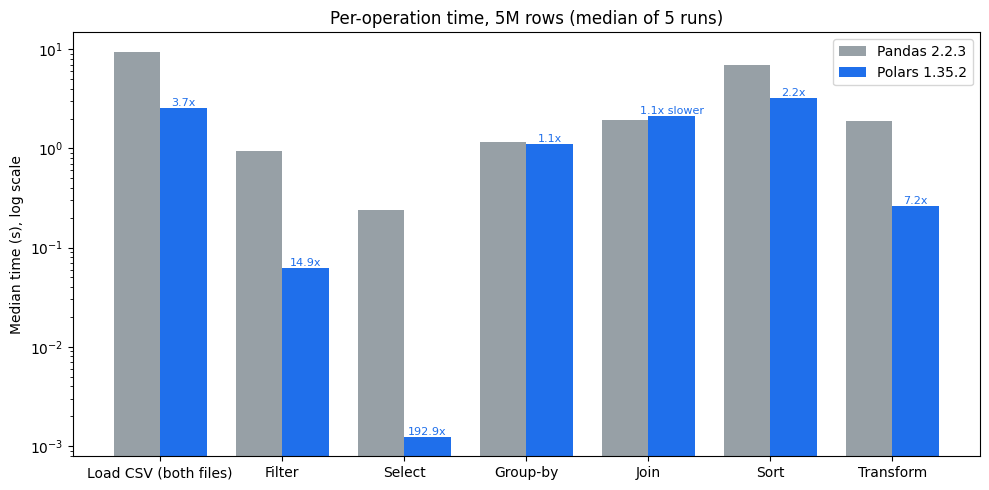

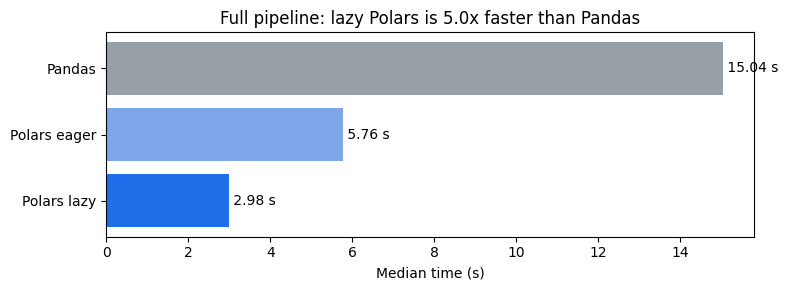

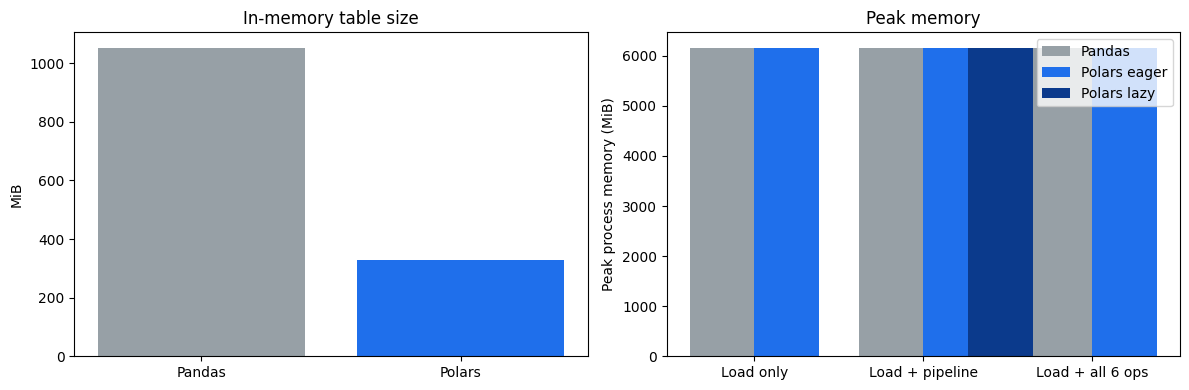

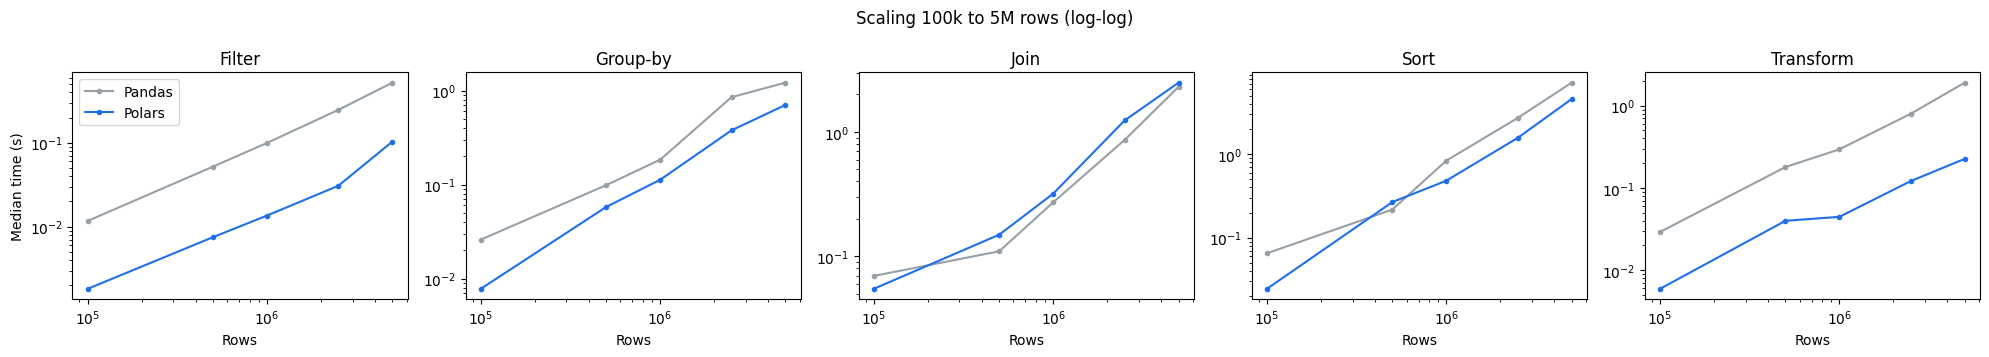

In [13]:
# 12. Charts
GREY, BLUE = "#97a0a6", "#1f6feb"

# (a) per-operation times
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(res)); w = 0.38
ax.bar(x - w/2, res["Pandas (s)"], w, label=f"Pandas {pd.__version__}", color=GREY)
ax.bar(x + w/2, res["Polars (s)"], w, label=f"Polars {pl.__version__}", color=BLUE)
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(res["Operation"])
ax.set_ylabel("Median time (s), log scale"); ax.set_title("Per-operation time, 5M rows (median of 5 runs)")
for i, s in enumerate(res["Polars speedup"]):
    ax.text(i + w/2, res["Polars (s)"][i], f"{s:.1f}x" if s >= 1 else f"{1/s:.1f}x slower", ha="center", va="bottom", fontsize=8, color=BLUE)
ax.legend(); plt.tight_layout(); plt.savefig("chart_operations.png", dpi=150); plt.show()

# (b) pipeline
fig, ax = plt.subplots(figsize=(8, 3))
labels, vals = ["Pandas", "Polars eager", "Polars lazy"], [t_pd, t_pe, t_pl]
ax.barh(labels[::-1], vals[::-1], color=[BLUE, "#7ea6e8", GREY])
for i, v in enumerate(vals[::-1]): ax.text(v, i, f" {v:.2f} s", va="center")
ax.set_xlabel("Median time (s)"); ax.set_title(f"Full pipeline: lazy Polars is {t_pd/t_pl:.1f}x faster than Pandas")
plt.tight_layout(); plt.savefig("chart_pipeline.png", dpi=150); plt.show()

# (c) memory
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].bar(["Pandas", "Polars"], [memtab.loc["orders table size in memory", "Pandas"], memtab.loc["orders table size in memory", "Polars eager"]], color=[GREY, BLUE])
axs[0].set_ylabel("MiB"); axs[0].set_title("In-memory table size")
peaks = memtab.loc[["Peak, load only", "Peak, load + pipeline", "Peak, load + all 6 operations"]]
xx = np.arange(len(peaks))
axs[1].bar(xx - w/2, peaks["Pandas"], w, color=GREY, label="Pandas")
axs[1].bar(xx + w/2, peaks["Polars eager"], w, color=BLUE, label="Polars eager")
axs[1].bar([1 + 1.2*w], [memtab.loc["Peak, load + pipeline", "Polars lazy"]], w, color="#0b3a8c", label="Polars lazy")
axs[1].set_xticks(xx); axs[1].set_xticklabels(["Load only", "Load + pipeline", "Load + all 6 ops"])
axs[1].set_ylabel("Peak process memory (MiB)"); axs[1].set_title("Peak memory"); axs[1].legend()
plt.tight_layout(); plt.savefig("chart_memory.png", dpi=150); plt.show()

# (d) scalability
fig, axs = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, (op, d) in zip(axs, scal.items()):
    ax.plot(d["n"], d["pandas"], "o-", color=GREY, label="Pandas", ms=3)
    ax.plot(d["n"], d["polars"], "o-", color=BLUE, label="Polars", ms=3)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(op); ax.set_xlabel("Rows")
axs[0].set_ylabel("Median time (s)"); axs[0].legend()
plt.suptitle("Scaling 100k to 5M rows (log-log)"); plt.tight_layout(); plt.savefig("chart_scaling.png", dpi=150); plt.show()

In [14]:
# 13. Summary table
summary = res.copy()
summary["Faster"] = np.where(summary["Polars speedup"] > 1.1, "Polars",
                      np.where(summary["Polars speedup"] < 0.9, "Pandas", "Tie"))
print(summary.round(3).to_string(index=False))
print("\nNotes:")
print("- Select: the Pandas version includes an explicit .copy(), so the gap is an upper bound.")
print("- Group-by / join timings can be noisy on a 2-core VM; see the 15-run re-check above.")
print("- Data is synthetic, so row counts (e.g. filter result) differ slightly from the PDF.")

            Operation  Pandas (s)  Polars (s)  Polars speedup Faster
Load CSV (both files)       9.471       2.538           3.731 Polars
               Filter       0.932       0.062          14.910 Polars
               Select       0.237       0.001         192.884 Polars
             Group-by       1.172       1.101           1.065    Tie
                 Join       1.937       2.114           0.916    Tie
                 Sort       6.987       3.201           2.183 Polars
            Transform       1.886       0.260           7.244 Polars

Notes:
- Select: the Pandas version includes an explicit .copy(), so the gap is an upper bound.
- Group-by / join timings can be noisy on a 2-core VM; see the 15-run re-check above.
- Data is synthetic, so row counts (e.g. filter result) differ slightly from the PDF.
